<a href="https://colab.research.google.com/github/khuluodk1998/SDA-DSC-211-StudentCode/blob/main/SDA_DSC_211_StudentCode_khuludalyousef_notebook04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")

بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


In [ ]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7", "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d", "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12")}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{revision}/{relative}", ROOT / relative, digest)
LAB_REVISION = "4f6892d5c02923b5f8e3c78f4fcead73b043570f"
SUPPORT_HASHES = {'scripts/day4_trust.py': '7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c', 'data/day4_shap_example.npz': 'de6eefb4f0b1dfd54d4a71e2b73cf8383cea6386e661f8af8662d478cd957e2b', 'data/day4_shap_example.json': '8169c70dc327a7ffdff748c365d71544fe951f3b196974e33f09dccb580a8122'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 4 setup verified | إعداد اليوم الرابع جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 4 setup verified | إعداد اليوم الرابع جاهز


In [ ]:
import json, platform, zipfile
from dataclasses import asdict
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display
from data_checks import validate_frame
from day2_validation import deduplicate_applications
from day4_trust import (TARGET, ROLES, TrustConfig, split_roles, fit_and_calibrate,
    probability_metrics, reliability_table, permutation_report, explain_sample, load_shap_example,
    ShapBudgetExpired, reason_codes, local_stability, cluster_bootstrap, choose_policy_threshold,
    transport_threshold, map_probability, review_audit, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = TrustConfig() if FAST_MODE else TrustConfig(trees=160, shap_rows=600, permutation_repeats=5, bootstrap_repeats=500)
USE_SHAP_EXAMPLE = False  # Discussion only; not a personal submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
parts, assignments = split_roles(train)
role_summary = pd.DataFrame([{"role": r, "rows": len(p), "customers": p.customer_id.nunique(),
    "positives": int(p[TARGET].sum()), "positive_rate": p[TARGET].mean(),
    "first_date": p.application_date.min(), "last_date": p.application_date.max()} for r, p in parts.items()])
display(role_summary)
print("Excluded gaps/customer overlaps:", int((assignments.role == "excluded_gap_or_customer").sum()))
model, calibrated_model, predictions, provenance = fit_and_calibrate(parts, contract, config)
evaluation = predictions[predictions.role == "evaluation"].copy()
policy_rows = predictions[predictions.role == "policy"].copy()
chosen_policy, policy_sweep = choose_policy_threshold(policy_rows)
mapping = provenance["calibration_mapping"]
calibrated_threshold = transport_threshold(chosen_policy["threshold"], mapping)
print("Model, sigmoid and policy threshold frozen before evaluation.")

,role,rows,customers,positives,positive_rate,first_date,last_date
0,fit,2516,1853,217,0.086248,2022-01-01,2023-04-01
1,calibration,584,538,40,0.068493,2023-07-01,2023-09-30
2,policy,589,566,55,0.093379,2024-01-01,2024-03-31
3,evaluation,1733,1520,139,0.080208,2024-07-01,2024-12-31


Excluded gaps/customer overlaps: 4578
Model, sigmoid and policy threshold frozen before evaluation.


,feature_group,mean_ap_drop,repeat_sd,training_gain
0,bureau_score,0.1270,0.0235,8922.6701
1,dti,0.0690,0.0200,6423.5164
2,loan_amount_sar,0.0140,0.0095,2372.2859
3,savings_balance_sar,0.0094,0.0032,2129.8893
4,prior_defaults,0.0065,0.0021,1109.2766
5,recent_inquiries,0.0064,0.0089,902.9509
6,income_sar,0.0062,0.0058,2214.5619
7,utilization_ratio,0.0057,0.0011,2035.9451
8,region_indicators_joint,0.0047,0.0020,360.9725
9,months_employed,0.0025,0.0044,2482.2264


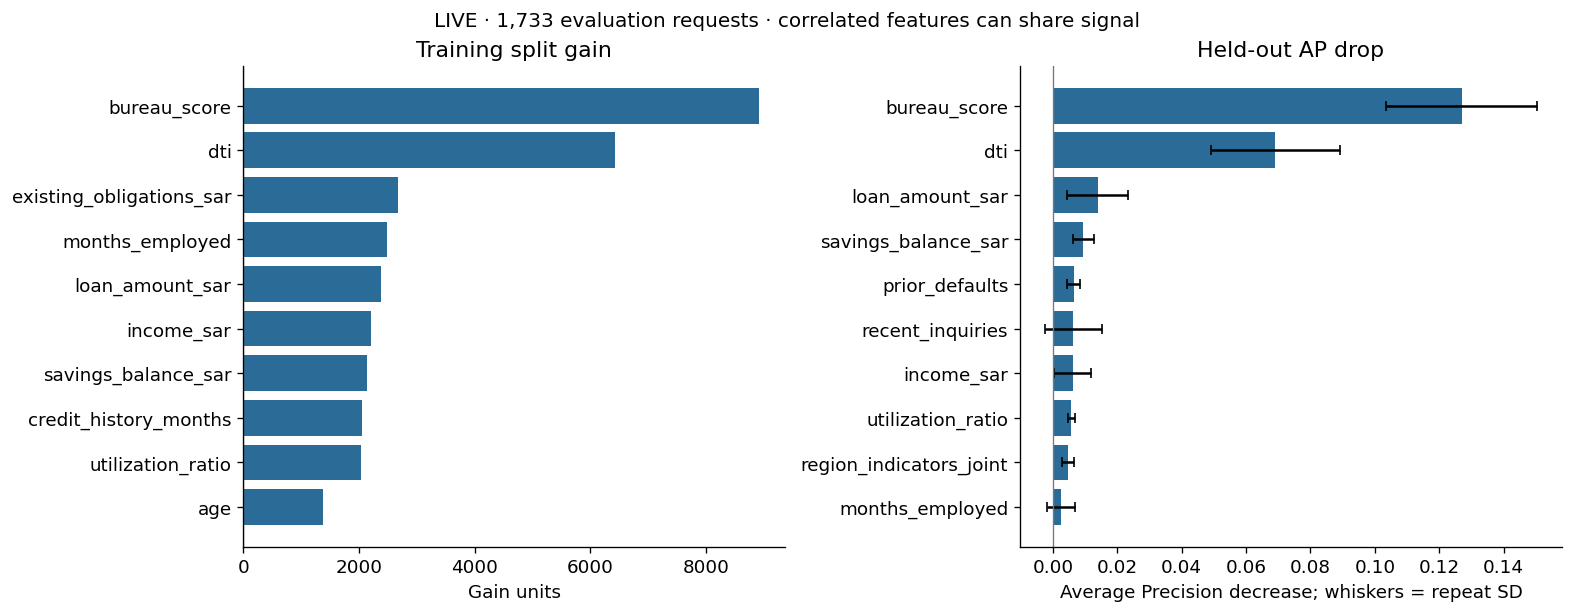

In [ ]:
permutation = permutation_report(model, parts["evaluation"], contract, config)
display(permutation[["feature_group", "mean_ap_drop", "repeat_sd", "training_gain"]].head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, value, title in [(axes[0], "training_gain", "Training split gain"), (axes[1], "mean_ap_drop", "Held-out AP drop")]:
    top = permutation.nlargest(10, value).sort_values(value)
    ax.barh(top.feature_group, top[value], color="#2b6b98",
            xerr=top.repeat_sd if value == "mean_ap_drop" else None, capsize=3)
    ax.axvline(0, color="#777", lw=.8); ax.set_title(title)
    ax.set_xlabel("Gain units" if value == "training_gain" else "Average Precision decrease; whiskers = repeat SD")
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · correlated features can share signal", fontsize=12)
fig.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight"); plt.show()


,feature,mean_absolute_shap_log_odds
4,bureau_score,0.9042
5,dti,0.5437
2,loan_amount_sar,0.3490
10,savings_balance_sar,0.2169
9,existing_obligations_sar,0.2022
8,prior_defaults,0.1830
6,months_employed,0.1584
1,income_sar,0.1549
7,recent_inquiries,0.1492
13,utilization_ratio,0.1287


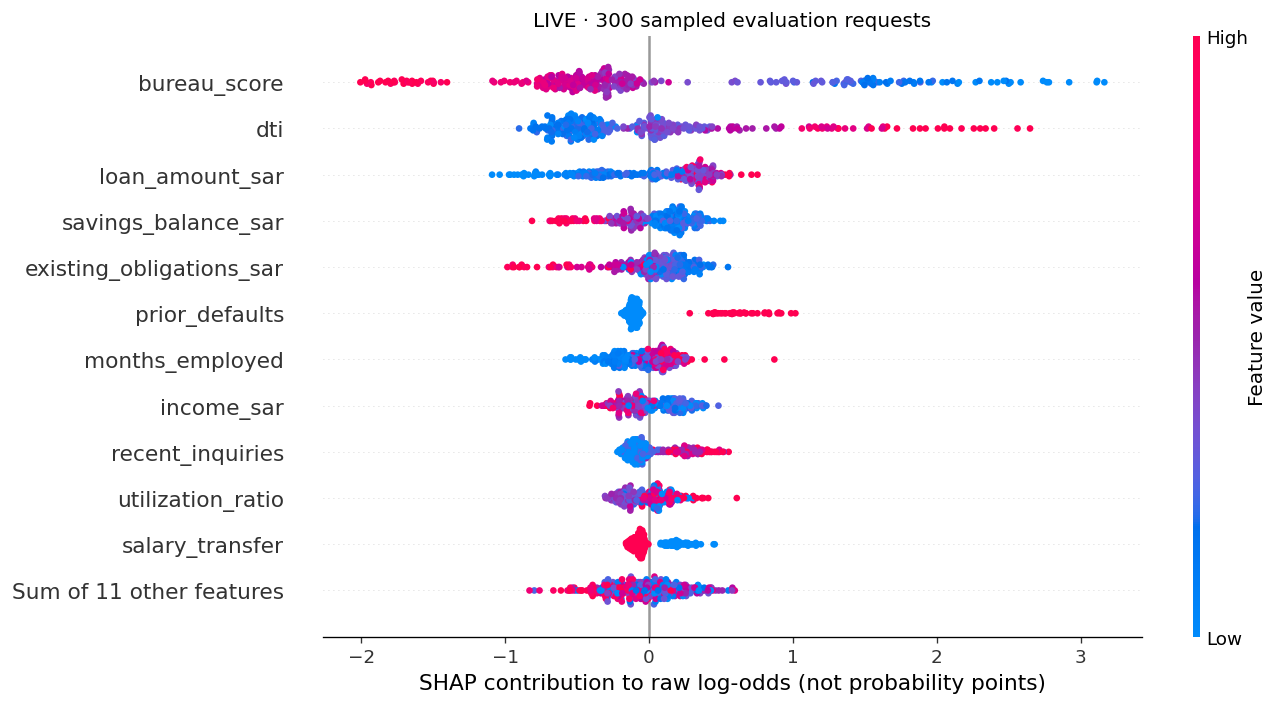

Maximum additivity error: 5.6968318951078345e-15


In [ ]:
try:
    if USE_SHAP_EXAMPLE:
        raise ShapBudgetExpired("Educational example requested.")
    shap_arrays, shap_metadata = explain_sample(model, parts["evaluation"], contract, config)
except ShapBudgetExpired:
    shap_arrays, shap_metadata = load_shap_example(ROOT / "data/day4_shap_example.npz",
        ROOT / "data/day4_shap_example.json", model, parts["evaluation"], contract, ASSESSMENT_MODE)

import shap
EXPLANATION_SOURCE = shap_metadata["source"]
if EXPLANATION_SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE — مثال موسوم للمناقشة، غير صالح للتسليم كتجربتك. أعد SHAP لاحقًا.")
explanation = shap.Explanation(values=shap_arrays["values"], base_values=shap_arrays["base_values"],
    data=shap_arrays["data"], feature_names=list(shap_arrays["feature_names"]))
shap_global = pd.DataFrame({"feature": shap_arrays["feature_names"],
    "mean_absolute_shap_log_odds": np.abs(shap_arrays["values"]).mean(axis=0)}).sort_values("mean_absolute_shap_log_odds", ascending=False)
display(shap_global.head(10).round(4))
plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False, plot_size=(11, 6.5))
plt.xlabel("SHAP contribution to raw log-odds (not probability points)")
plt.title(f"{EXPLANATION_SOURCE} · {len(shap_arrays['application_ids'])} sampled evaluation requests", fontsize=12)
plt.savefig(ARTIFACTS / "shap_beeswarm.png", bbox_inches="tight"); plt.show()
print("Maximum additivity error:", shap_metadata["max_additivity_error"])

TR-009585 | raw score=0.9031 | calibrated probability=0.4795


,feature,value_used,was_imputed,contribution_log_odds,reason_ar
0,bureau_score,497.0000,False,2.269325,استخدم النموذج درجة ائتمانية اصطناعية عند الطل...
1,dti,1.2806,False,1.198145,استخدم النموذج نسبة الالتزام مع القسط المقترح ...
2,loan_amount_sar,93437.2900,False,0.200725,استخدم النموذج مبلغ التمويل المطلوب بالقيمة 93...


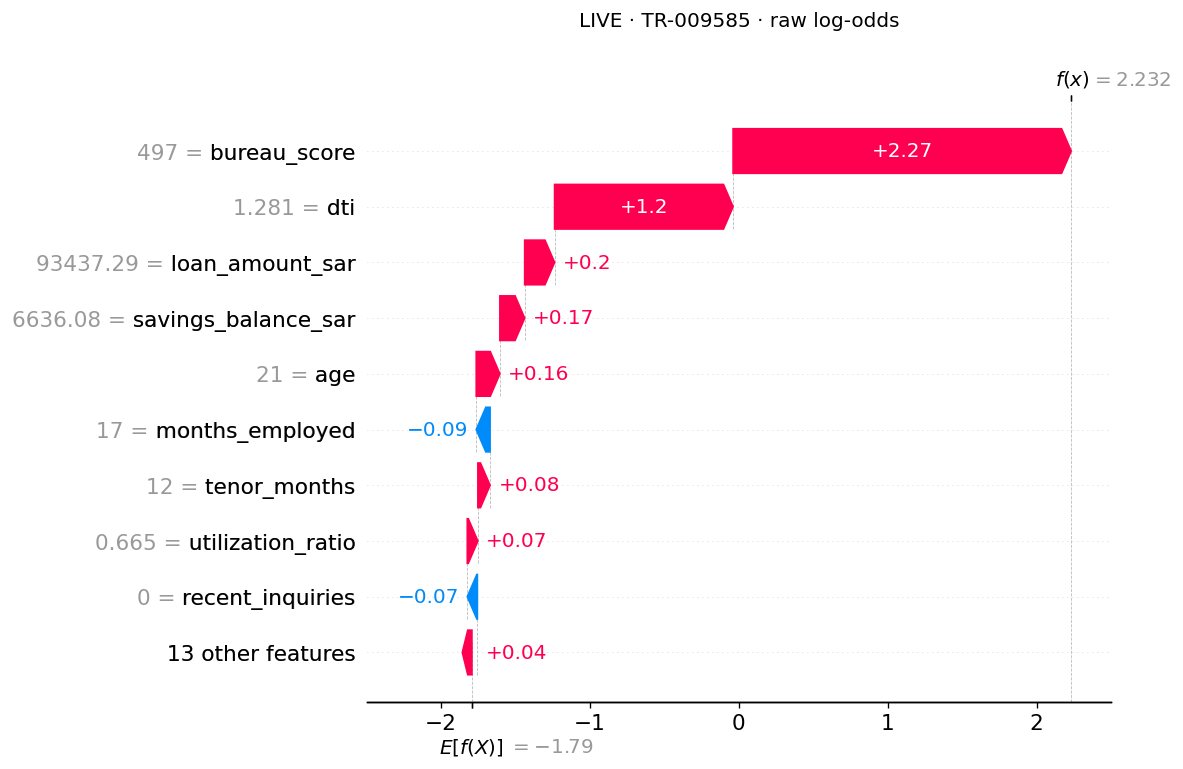

,perturbation,bureau_score_used,raw_probability,calibrated_probability,top_positive_features,shared_top_reasons,reference_reasons,source
0,bureau_score +0,497.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
1,bureau_score -1,496.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
2,bureau_score +1,498.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE


In [ ]:
local_index = int(np.argmax(shap_arrays["raw_margin"]))
local_id = str(shap_arrays["application_ids"][local_index])
case = parts["evaluation"].set_index("application_id", drop=False).loc[[local_id]]
descriptions = {f["name"]: f["description_ar"] for f in contract["features"]}
reasons = reason_codes(shap_arrays["values"][local_index], shap_arrays["feature_names"],
    shap_arrays["data"][local_index], descriptions)
reasons["application_id"] = local_id
reasons["was_imputed"] = [bool(case.iloc[0][feature] != case.iloc[0][feature]) for feature in reasons.feature]
reasons["source"] = EXPLANATION_SOURCE
raw_local = float(expit(shap_arrays["raw_margin"][local_index]))
cal_local = float(map_probability(raw_local, mapping))
print(f"{local_id} | raw score={raw_local:.4f} | calibrated probability={cal_local:.4f}")
display(reasons[["feature", "value_used", "was_imputed", "contribution_log_odds", "reason_ar"]])
plt.figure()
shap.plots.waterfall(explanation[local_index], max_display=10, show=False)
plt.title(f"{EXPLANATION_SOURCE} · {local_id} · raw log-odds", fontsize=12, pad=45)
plt.savefig(ARTIFACTS / "shap_waterfall.png", bbox_inches="tight"); plt.show()
if EXPLANATION_SOURCE == "LIVE":
    local_checks = local_stability(model, case, contract, mapping)
    local_checks["source"] = "LIVE"
    display(local_checks)
else:
    local_checks = pd.DataFrame(columns=["perturbation", "bureau_score_used", "raw_probability", "calibrated_probability",
        "top_positive_features", "shared_top_reasons", "reference_reasons", "source"])
    print("Local perturbation check skipped in example mode; do not claim it ran.")


,rows,positives,roc_auc,average_precision,brier,ece,log_loss
raw,1733,139,0.770804,0.258677,0.113027,0.146871,0.357993
sigmoid,1733,139,0.770804,0.258677,0.067112,0.022486,0.246749


Measured change (after - before): Brier -0.04592, ECE -0.12438


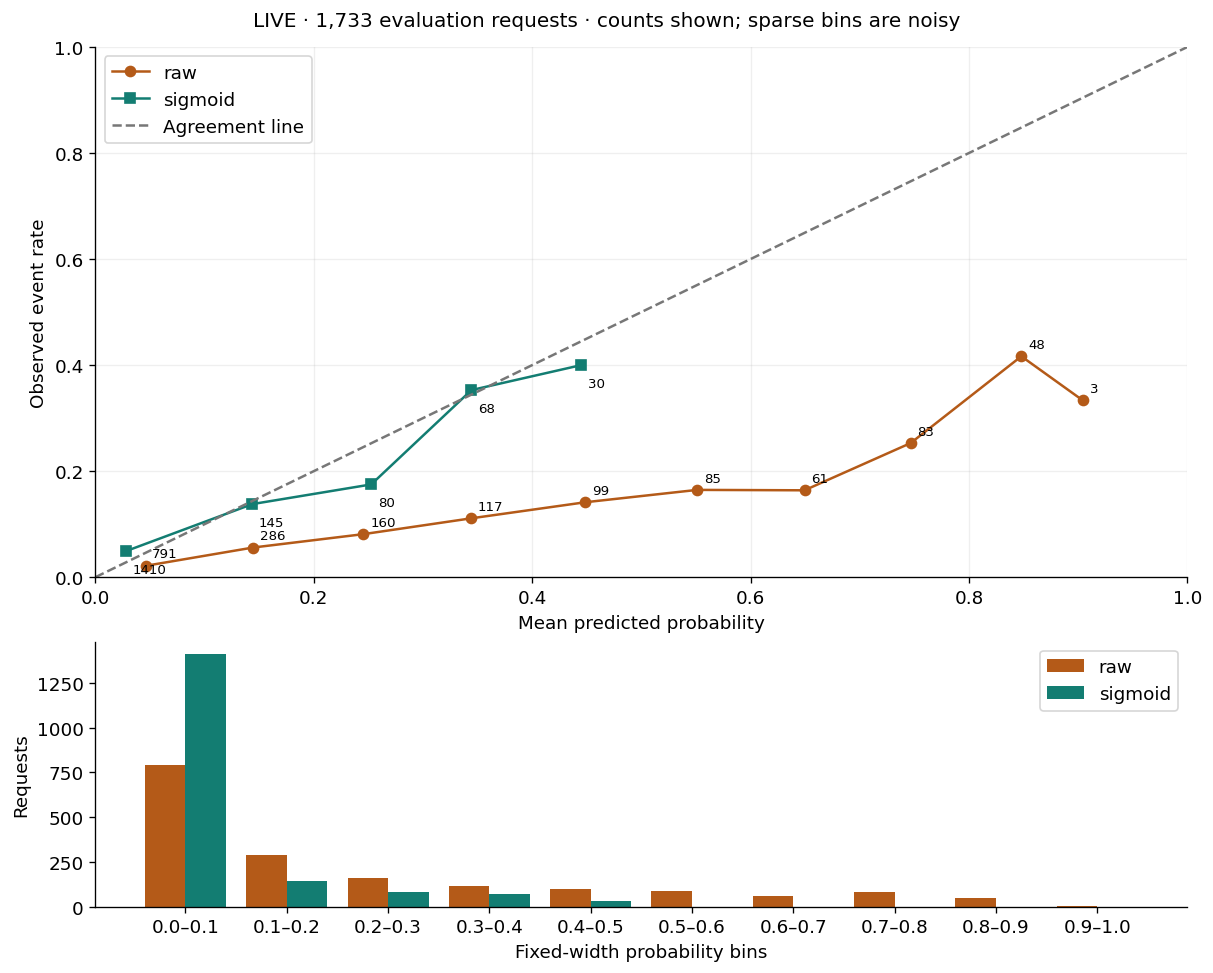

In [ ]:
calibration_metrics, bin_tables = {}, []
for label, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
    calibration_metrics[label] = probability_metrics(evaluation[TARGET], evaluation[column])
    table = reliability_table(evaluation[TARGET], evaluation[column]); table["variant"] = label
    bin_tables.append(table)
reliability = pd.concat(bin_tables, ignore_index=True)
display(pd.DataFrame(calibration_metrics).T[["rows", "positives", "roc_auc", "average_precision", "brier", "ece", "log_loss"]].round(5))
brier_delta = calibration_metrics["sigmoid"]["brier"] - calibration_metrics["raw"]["brier"]
ece_delta = calibration_metrics["sigmoid"]["ece"] - calibration_metrics["raw"]["ece"]
print(f"Measured change (after - before): Brier {brier_delta:+.5f}, ECE {ece_delta:+.5f}")
fig, axes = plt.subplots(2, 1, figsize=(10, 8), layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
for label, color, marker in [("raw", "#b45a18", "o"), ("sigmoid", "#137d72", "s")]:
    bins = reliability[reliability.variant == label]; nonempty = bins[bins['count'] > 0]
    axes[0].plot(nonempty.mean_probability, nonempty.observed_rate, marker=marker, color=color, label=label)
    for row in nonempty.itertuples():
        axes[0].annotate(str(row.count), (row.mean_probability, row.observed_rate), xytext=(4, 5 if label == "raw" else -13), textcoords="offset points", fontsize=8)
    positions = bins['bin'] + (-.2 if label == "raw" else .2)
    axes[1].bar(positions, bins['count'], width=.4, color=color, label=label)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#777", label="Agreement line")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed event rate")
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].set(xticks=np.arange(10), xticklabels=[f"{i/10:.1f}–{(i+1)/10:.1f}" for i in range(10)], ylabel="Requests", xlabel="Fixed-width probability bins")
axes[1].legend()
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · counts shown; sparse bins are noisy", fontsize=12)
fig.savefig(ARTIFACTS / "reliability_curve.png", bbox_inches="tight"); plt.show()

,period,variant,rows,positives,average_precision,brier,ece
0,2024Q3,raw,836,78,0.27457,0.11528,0.13397
1,2024Q3,sigmoid,836,78,0.27457,0.07760,0.03229
2,2024Q4,raw,897,61,0.27050,0.11093,0.15890
3,2024Q4,sigmoid,897,61,0.27050,0.05734,0.02434


Paired customer-cluster 95% percentile intervals:


,lower,upper
raw_ap,0.197442,0.337854
calibrated_ap,0.197442,0.337854
brier_change,-0.054177,-0.037409


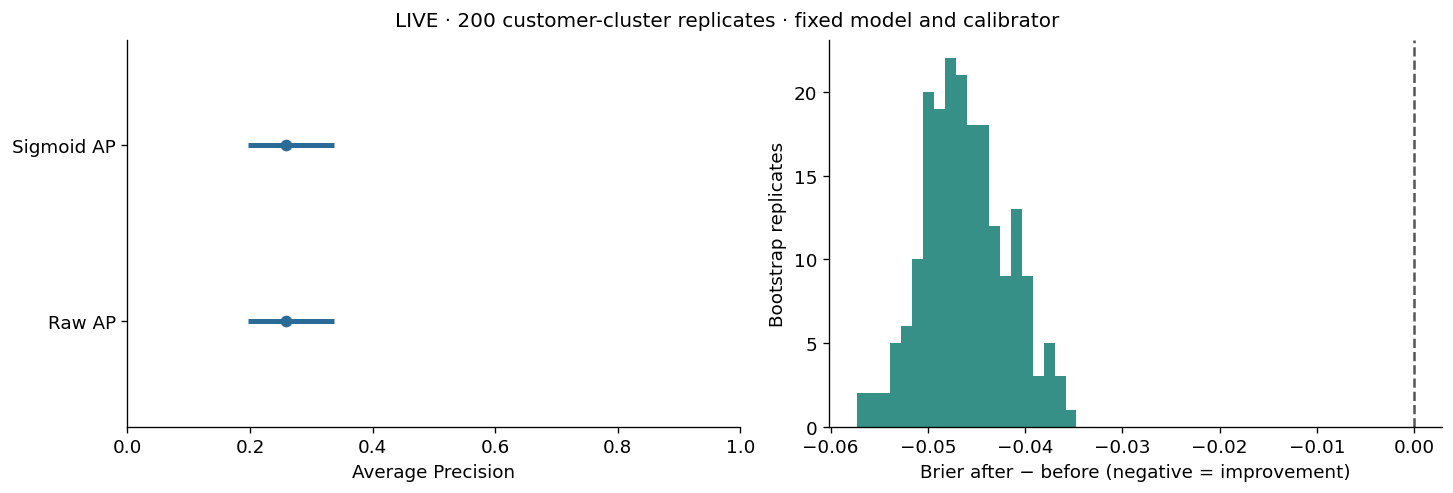

In [ ]:
bootstrap, stability_summary = cluster_bootstrap(evaluation, config)
period_rows = []
for period, group in evaluation.groupby(pd.to_datetime(evaluation.application_date).dt.to_period("Q").astype(str)):
    for variant, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
        period_rows.append({"period": period, "variant": variant, **probability_metrics(group[TARGET], group[column])})
period_metrics = pd.DataFrame(period_rows)
display(period_metrics[["period", "variant", "rows", "positives", "average_precision", "brier", "ece"]].round(5))
stability_summary["period_ap_sample_sd"] = {v: float(g.average_precision.std(ddof=1)) for v, g in period_metrics.groupby("variant")}
print("Paired customer-cluster 95% percentile intervals:")
display(pd.DataFrame({key: stability_summary[key] for key in ("raw_ap", "calibrated_ap", "brier_change")}).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for i, key in enumerate(("raw_ap", "calibrated_ap")):
    interval = stability_summary[key]
    point = calibration_metrics["raw" if i == 0 else "sigmoid"]["average_precision"]
    if interval is not None:
        axes[0].hlines(i, interval["lower"], interval["upper"], color="#2b6b98", lw=3)
    axes[0].plot(point, i, "o", color="#2b6b98")
axes[0].set(yticks=[0, 1], yticklabels=["Raw AP", "Sigmoid AP"], xlabel="Average Precision", xlim=(0, 1), ylim=(-.6, 1.6))
axes[1].hist(bootstrap.brier_change, bins=20, color="#137d72", alpha=.85)
axes[1].axvline(0, color="#555", linestyle="--"); axes[1].set(xlabel="Brier after − before (negative = improvement)", ylabel="Bootstrap replicates")
fig.suptitle(f"LIVE · {stability_summary['valid']} customer-cluster replicates · fixed model and calibrator", fontsize=12)
fig.savefig(ARTIFACTS / "stability_summary.png", bbox_inches="tight"); plt.show()

,threshold,flagged,fn,fp,loss_units,capacity,feasible,calibrated_threshold,selection_role
0,0.588195,68,34,47,387.0,70,True,0.17331,policy


,period,rows,capacity,risk_flags,near_threshold,candidate_review,risk_within_capacity,candidate_within_capacity,loss_units
0,2024Q3,836,100,97,23,109,True,False,536.0
1,2024Q4,897,107,109,21,122,False,False,444.0


CAPACITY_REVIEW_REQUIRED | Do not retune on evaluation.


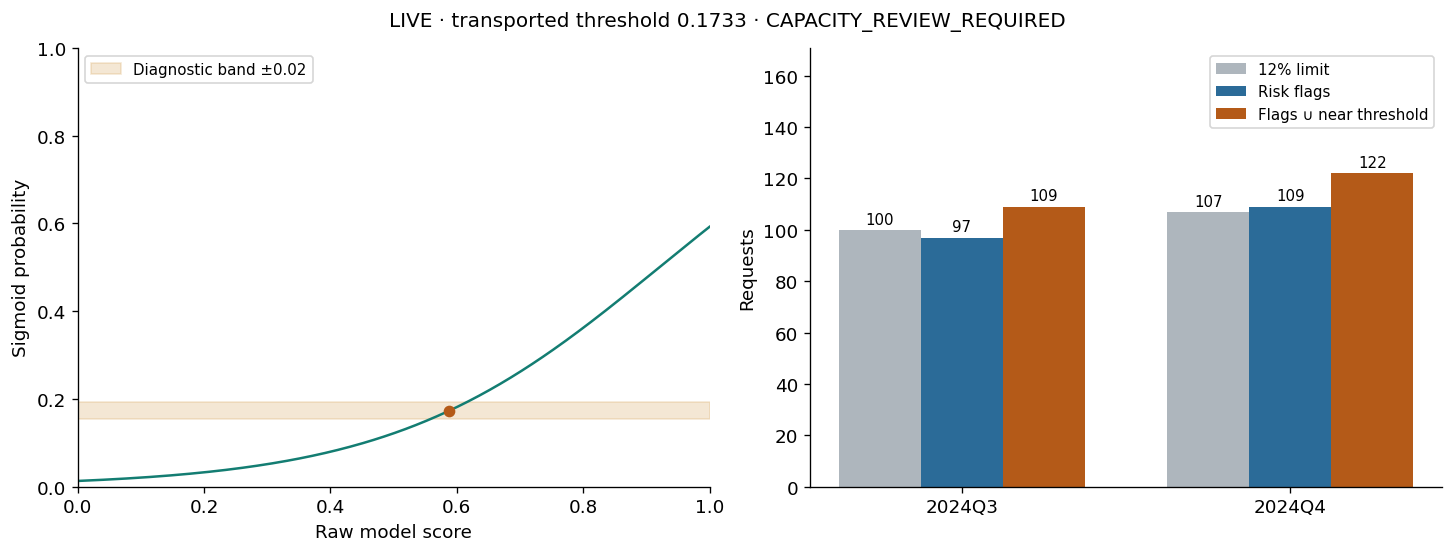

In [ ]:
review_flags, capacity_audit, review_band = review_audit(evaluation, chosen_policy["threshold"],
    calibrated_threshold, config.review_half_width)
policy_status = "CAPACITY_REVIEW_REQUIRED" if not capacity_audit.candidate_within_capacity.all() else "WITHIN_OBSERVED_CAPACITY"
display(pd.DataFrame([{**chosen_policy, "calibrated_threshold": calibrated_threshold, "selection_role": "policy"}]))
display(capacity_audit)
print(policy_status, "| Do not retune on evaluation.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
grid = np.linspace(0, 1, 300)
axes[0].plot(grid, map_probability(grid, mapping), color="#137d72")
axes[0].axhspan(review_band['lower'], review_band['upper'], color="#d7a354", alpha=.25, label="Diagnostic band ±0.02")
axes[0].plot(chosen_policy['threshold'], calibrated_threshold, 'o', color="#b45a18")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Raw model score", ylabel="Sigmoid probability")
axes[0].legend(loc="upper left", fontsize=9)
x = np.arange(len(capacity_audit))
for offset, column, label, color in [(-.25, 'capacity', '12% limit', '#aeb6bd'), (0, 'risk_flags', 'Risk flags', '#2b6b98'), (.25, 'candidate_review', 'Flags ∪ near threshold', '#b45a18')]:
    bars = axes[1].bar(x+offset, capacity_audit[column], width=.25, label=label, color=color)
    axes[1].bar_label(bars, padding=2, fontsize=9)
axes[1].set(xticks=x, xticklabels=capacity_audit.period, ylabel="Requests", ylim=(0, capacity_audit.candidate_review.max()*1.4))
axes[1].legend(fontsize=9)
fig.suptitle(f"LIVE · transported threshold {calibrated_threshold:.4f} · {policy_status}", fontsize=12)
fig.savefig(ARTIFACTS / "review_zone.png", bbox_inches="tight"); plt.show()

In [ ]:

responses = {
    "global_local": (
        "Global explanations describe which features influence "
        "payment-risk predictions across the dataset. Local "
        "explanations describe how individual features contribute "
        "to one person's predicted risk. Global importance does "
        "not mean that the same feature dominates every prediction."
    ),

    "output_units": (
        "SHAP values explain model outputs relative to a background "
        "reference. Their units depend on the explainer configuration: "
        "they may represent raw model scores, log-odds, or probability "
        "differences. The actual output unit and background dataset "
        "must be verified before interpreting the values."
    ),

    "reason_limits": (
        "Reason statements summarize the main factors associated "
        "with a prediction, but they do not establish causation. "
        "Correlated features can share or redistribute importance, "
        "so their individual contributions should not be treated "
        "as independent causal effects."
    ),

    "calibration_evidence": (
        "Calibration should be evaluated on the separate evaluation "
        "period by comparing predicted risk with observed late-payment "
        "rates. The calibration results and sample denominators "
        "are needed to determine whether predicted probabilities "
        "match observed outcomes."
    ),

    "stability": (
        "The stability interval describes variation under the "
        "specific resampling procedure used in the experiment. "
        "It does not automatically include future economic changes, "
        "new customer populations, data drift, or uncertainty "
        "outside the evaluated sample."
    ),

    "review_capacity": (
        "The review zone identifies cases requiring additional "
        "assessment rather than an automatic decision. "
        "A wider review zone increases the number of cases "
        "requiring manual review and may exceed period capacity. "
        "Its actual impact should be calculated using the number "
        "of review-zone cases divided by the available review capacity."
    )
}

checkpoint = reflection_check(responses, EXPLANATION_SOURCE)

print(checkpoint["status"], "| Fields to complete:", checkpoint["missing"])


READY_FOR_REVIEW | Fields to complete: []


In [ ]:
def json_safe(value):
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)): return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, (float, np.floating)): return float(value) if np.isfinite(value) else None
    return value

technical_status = "TECHNICAL_READY" if EXPLANATION_SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
calibration_payload = {"source": "LIVE", "evaluation_role": "evaluation", "metrics": calibration_metrics,
    "mapping": mapping, "policy_selection": chosen_policy, "calibrated_threshold": calibrated_threshold,
    "review_band": review_band, "capacity_status": policy_status, "brier_change": brier_delta, "ece_change": ece_delta,
    "prior_course_exposure": True, "not_a_final_untouched_test": True}
run = {"technical_status": technical_status, "learner_status": checkpoint["status"],
    "explanation_source": EXPLANATION_SOURCE, "model_calibration_source": "LIVE", "config": asdict(config),
    "assessment_mode": ASSESSMENT_MODE, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION, "python": platform.python_version(),
    "elapsed_seconds": round(time.perf_counter()-RUN_STARTED, 2), "capacity_status": policy_status,
    "challenge_used_for_modeling": False, "no_automatic_grade": True}
csv_outputs = {"day4_roles.csv": assignments, "day4_predictions.csv": predictions,
    "permutation_importance.csv": permutation, "day4_shap_global.csv": shap_global.assign(source=EXPLANATION_SOURCE),
    "day4_reason_codes.csv": reasons, "day4_local_stability.csv": local_checks,
    "day4_reliability_bins.csv": reliability, "day4_period_metrics.csv": period_metrics,
    "day4_bootstrap.csv": bootstrap, "day4_policy_sweep.csv": policy_sweep,
    "day4_review_flags.csv": review_flags, "day4_capacity.csv": capacity_audit}
for filename, table in csv_outputs.items(): table.to_csv(ARTIFACTS / filename, index=False)
np.savez_compressed(ARTIFACTS / "shap_values_sample.npz", **shap_arrays)
model.named_steps["model"].booster_.save_model(str(ARTIFACTS / "day4_model.txt"))
json_outputs = {"calibration_metrics.json": calibration_payload, "day4_shap_metadata.json": shap_metadata,
    "day4_stability_summary.json": stability_summary, "day4_provenance.json": provenance,
    "day4_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day4_run.json": run}
for filename, payload in json_outputs.items():
    (ARTIFACTS / filename).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
answer = lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
status_text = "مثال تعليمي غير صالح للتسليم كتجربة شخصية" if EXPLANATION_SOURCE != "LIVE" else ("مسودة — أكمل تفسيرك" if checkpoint['missing'] else "جاهز للمراجعة؛ لا يعني اعتمادًا أو درجة")
reason_text = "\n".join(f"- {r.reason_ar} (SHAP={r.contribution_log_odds:+.4f} log-odds؛ قيمة معوضة: {r.was_imputed})" for r in reasons.itertuples())
capacity_text = "\n".join(f"- {r.period}: السقف {r.capacity}، الإشارات {r.risk_flags}، اتحاد المراجعة {r.candidate_review}." for r in capacity_audit.itertuples())
report = f"""# تقريرك: التفسير والمعايرة — Tamweel Lite

**الحالة:** {status_text}

**مصدر التفسير:** {EXPLANATION_SOURCE}. **النموذج والمعايرة:** LIVE. **السعة:** {policy_status}.

## النموذج والأدوار
LightGBM موزون، {config.trees} شجرة. الهدف حدث تعثر اصطناعي خلال90 يومًا بعد الطلب. الأدوار منفصلة زمنيًا وبالعملاء: تدريب {len(parts['fit'])}، معايرة {len(parts['calibration'])} ({int(parts['calibration'][TARGET].sum())} موجب)، سياسة {len(parts['policy'])}، تقييم {len(evaluation)}. الفجوات والتداخلات مستبعدة. سبق استخدام بيانات التقييم في الدورة، فهي ليست اختبارًا نهائيًا لم يمسّ.

## التفسير العام والمحلي
Permutation يقيس انخفاضAP على التقييم؛ إشارات المنطقة تُبدّل معًا. SHAP يفسر النموذج الخام بوحدةlog-odds وخلفية مسارات أشجار التدريب. base+sum(SHAP)=raw margin، ثمsigmoid للمجموع فقط. القيم ليست نقاط احتمال ولا تفسيرًا مباشرًا للنموذج المعاير.

{answer('global_local')}

{answer('output_units')}

الطلب الاصطناعي {local_id}: الدرجة الخام {raw_local:.5f} والاحتمال المعاير {cal_local:.5f}. اختير أعلى درجة داخل عينةSHAP دون استخدام النتيجة الفعلية.
{reason_text}

{answer('reason_limits')}

## دليل المعايرة
على {len(evaluation)} صفًا و{int(evaluation[TARGET].sum())} موجب: Brier {calibration_metrics['raw']['brier']:.6f} → {calibration_metrics['sigmoid']['brier']:.6f}؛ ECE {calibration_metrics['raw']['ece']:.6f} → {calibration_metrics['sigmoid']['ece']:.6f}. عشر حاويات متساوية العرض مع أعدادها فيday4_reliability_bins.csv. AP {calibration_metrics['raw']['average_precision']:.6f} → {calibration_metrics['sigmoid']['average_precision']:.6f}؛ ROC-AUC {calibration_metrics['raw']['roc_auc']:.6f} → {calibration_metrics['sigmoid']['roc_auc']:.6f}. هذه نتائج هذه العينة وليست ضمانًا لتحسن مستقبلي.

{answer('calibration_evidence')}

## الاستقرار
{stability_summary['valid']} تكرارbootstrap صالح بسحب العملاء؛ فترات مئينية95% مع تثبيت النموذج والمعاير. لا تشمل تعلم النموذج أو المعايرة أو الانجراف المستقبلي، ولا تصف احتمال فرد. انحرافAP بين ربعي التقييم وصفي فقط. اختبارbureau_score±1 {'نُفذ؛ راجع day4_local_stability.csv' if EXPLANATION_SOURCE == 'LIVE' else 'لم ينفذ في وضع المثال'}.

{answer('stability')}

## العتبة ومنطقة المراجعة
العتبة الخام {chosen_policy['threshold']!r} اختيرت علىpolicy بخسارة10×FN+FP وسقف12% ثم نُقلت إلى {calibrated_threshold!r}. لم تعدل باستخدام التقييم. المنطقة[{review_band['lower']:.5f}, {review_band['upper']:.5f}] تشخيصية بعرض±0.02 وليست فترة ثقة. الاتحاد يحسب الطلب مرة واحدة.
{capacity_text}

{answer('review_capacity')}

عند تجاوز السعة، وثّق الحاجة إلى تصميم سياسة جديدة على بيانات تطوير وتقييمها بدليل جديد. لا ترفع السقف ولا تقص الحالات بعد رؤية النتيجة. التفسير ليس سببية أو شهادة عدالة، والخسارة وحدات تعليمية لا رسوم أو خصم درجات. لا يستخدم هذا التمرين لتمويل حقيقي.
"""
(REPORTS / "INTERPRETABILITY_REPORT.md").write_text(report, encoding="utf-8")
figures = ["permutation_importance.png", "shap_beeswarm.png", "shap_waterfall.png", "reliability_curve.png", "stability_summary.png", "review_zone.png"]
artifact_files = list(csv_outputs) + list(json_outputs) + figures + ["environment.json", "shap_values_sample.npz", "day4_model.txt"]
with zipfile.ZipFile(ARTIFACTS / "day4_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in artifact_files: bundle.write(ARTIFACTS / filename, "artifacts/" + filename)
    bundle.write(REPORTS / "INTERPRETABILITY_REPORT.md", "reports/INTERPRETABILITY_REPORT.md")
print(f"{technical_status} | {checkpoint['status']} | {EXPLANATION_SOURCE} | CPU")
print(f"Saved {len(artifact_files)+1} files in day4_artifacts.zip | {policy_status}")


TECHNICAL_READY | READY_FOR_REVIEW | LIVE | CPU
Saved 28 files in day4_artifacts.zip | CAPACITY_REVIEW_REQUIRED


In [8]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
PREVIOUS_SUPPORT = {
 "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7", "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
 "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d", "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
 "scripts/day4_trust.py": ("4f6892d5c02923b5f8e3c78f4fcead73b043570f", "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c")}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{revision}/{relative}", ROOT / relative, digest)
LAB_REVISION = "f486fc50dd9ac8403016facc58cf6a62beb4abf4"
SUPPORT_HASHES = {'scripts/day5_final.py': '71553cffc66f972e77d470a347cae40e4ca2802026535b48cb40168a59362b10', 'scripts/day5_delivery.py': 'eba5b5820550b44ccca2cf7f5d56a826c015de552e5db8d7e4c27a6e956ecd21', 'scripts/inference.py': 'abf1af0bca47bcd08e66f8218276773d39083e6f42f42caeea5d8b2db70c0a6a', 'scripts/replay_final.py': 'adcb2e40aff819439068cd7a2aca9fcb6f8632b0c551a9d04f7bd63efc8506fb', 'scripts/rebuild_final.py': 'ac18b78160dbc33b720f3e1038667110760832c095e23c1ea7f909d4c5760dfd', 'data/tamweel_oof_matrix.csv': 'f8c9429c7eed015d53978fba93b4b32ed3266fa15b63471b03881ab5c09804b5', 'data/day5_oof_example.json': '9edcb173ab5aa504af3ef79c4f3371cd285fa4b171be1bcc6dd9da1d7fb0394d', 'presentation/FINAL_PRESENTATION_TEMPLATE.md': '8d3df570727b18db097c9c78ed518ac09bd8766dbdba2817ae8883e43ed5de39', 'presentation/FINAL_PRESENTATION_GUIDE.md': '1d24149ef2e56df0a6c44e000157135904b8ba3d252445e4367a6de547c87b19'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Completion of Day 4 setup is verified and ready at the same standard as Day 5| أستكمال إعداد اليوم الرابع كاليوم الخامس جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Completion of Day 4 setup is verified and ready at the same standard as Day 5| أستكمال إعداد اليوم الرابع كاليوم الخامس جاهز


In [3]:
import json, platform, time, zipfile
from dataclasses import asdict
from hashlib import sha256
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
from data_checks import validate_frame
from day5_final import (BASE, ENSEMBLES, TARGET, FinalConfig, EnsembleBudgetExpired, split_final_roles,
    nested_comparison, load_example, worth_it, selected_oof, fit_final, export_model,
    predict_final, transport_threshold, apply_batch_policy, write_json)
from day3_decision import CostPolicy, threshold_sweep, select_threshold, region_audit, period_audit
from day4_trust import probability_metrics, reliability_table, map_probability
from day5_delivery import (RESPONSES, reflection_check, import_daily_evidence, evidence_status,
    validate_submission, replay_submission, create_bundle, verify_bundle)

STARTED = time.perf_counter()
contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train = pd.read_csv(ROOT / "data/tamweel_train.csv")
challenge = pd.read_csv(ROOT / "data/tamweel_challenge.csv")
validate_frame(train, contract, "train"); validate_frame(challenge, contract, "challenge")
assert not set(train.customer_id) & set(challenge.customer_id)
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = FinalConfig() if FAST_MODE else FinalConfig(trees=160, seconds=240)
USE_OOF_EXAMPLE = False  # For discussion only; cannot export a submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
pool, calibration, roles = split_final_roles(train)
ARTIFACTS, REPORTS, SUBMISSION = ROOT / "artifacts", ROOT / "reports", ROOT / "submission"
for folder in (ARTIFACTS, REPORTS, SUBMISSION): folder.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
display(pd.DataFrame([{"role":name,"rows":len(frame),"customers":frame.customer_id.nunique(),
    "positives":int(frame[TARGET].sum()),"first_date":frame.application_date.min(),"last_date":frame.application_date.max()}
    for name,frame in [("fit + selection",pool),("calibration only",calibration)]]))
print("Excluded rows:", int(roles.role.str.startswith("excluded").sum()))

,role,rows,customers,positives,first_date,last_date
0,fit + selection,6576,3931,537,2022-01-01,2024-04-01
1,calibration only,836,788,78,2024-07-01,2024-09-30


Excluded rows: 2588


In [4]:
try:
    if USE_OOF_EXAMPLE:
        raise EnsembleBudgetExpired("Educational OOF example requested.")
    oof, fold_scores, oof_provenance = nested_comparison(pool, contract, config)
except EnsembleBudgetExpired:
    oof, fold_scores, oof_provenance = load_example(ROOT / "data/tamweel_oof_matrix.csv",
        ROOT / "data/day5_oof_example.json", pool, config, assessment_mode=ASSESSMENT_MODE)
SOURCE = oof.source.iloc[0]
if SOURCE != "LIVE": print("EDUCATIONAL_EXAMPLE — للمناقشة فقط، دون نموذج نهائي أو تسليم.")
display(oof[["application_id","fold",*BASE,*ENSEMBLES]].head().round(4))
print(f"{SOURCE}: {len(oof):,} OOF rows across three forward periods; warm-up rows have no outer OOF.")


,application_id,fold,LightGBM,XGBoost,Logistic,Equal,Weighted,Stack
0,TR-001160,1,0.0321,0.0444,0.0467,0.0410,0.0461,0.0684
1,TR-003137,1,0.1149,0.1798,0.1547,0.1498,0.1610,0.1085
2,TR-004529,1,0.0457,0.0854,0.0887,0.0733,0.0879,0.0796
3,TR-004666,1,0.0123,0.0150,0.0062,0.0112,0.0084,0.0593
4,TR-008372,1,0.0373,0.0538,0.0336,0.0416,0.0387,0.0674


LIVE: 2,155 OOF rows across three forward periods; warm-up rows have no outer OOF.


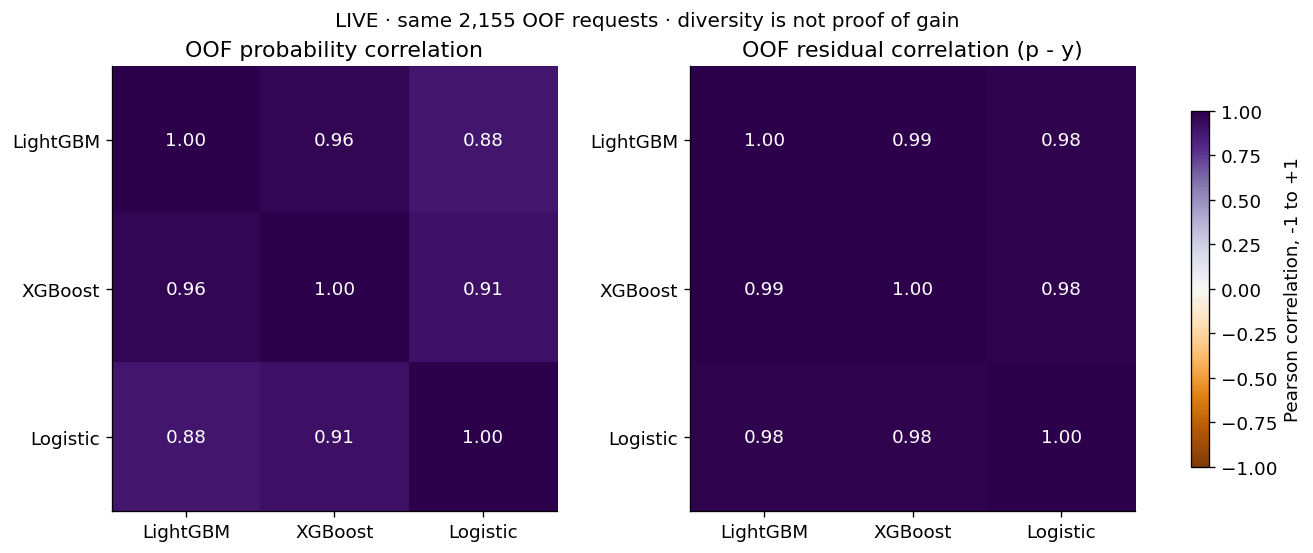

In [5]:
correlation = oof[list(BASE)].corr()
residual_correlation = oof[list(BASE)].sub(oof[TARGET], axis=0).corr()
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
for ax, table, title in [(axes[0],correlation,"OOF probability correlation"),(axes[1],residual_correlation,"OOF residual correlation (p - y)")]:
    im = ax.imshow(table, vmin=-1, vmax=1, cmap="PuOr")
    ax.set_xticks(range(3),BASE); ax.set_yticks(range(3),BASE); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            value=table.iloc[i,j]
            ax.text(j,i,f"{value:.2f}",ha="center",va="center",color="white" if abs(value)>.6 else "#222")
fig.colorbar(im,ax=axes,shrink=.8,label="Pearson correlation, -1 to +1")
fig.suptitle(f"{SOURCE} · same {len(oof):,} OOF requests · diversity is not proof of gain",fontsize=12)
fig.savefig(ARTIFACTS / "day5_diversity.png",bbox_inches="tight"); plt.show()

,candidate,mean_ap,fold_sd,mean_brier,mean_ece,lift_vs_single,passes_gate
0,LightGBM,0.34549,0.04348,0.06608,0.02311,-0.04617,False
1,XGBoost,0.35263,0.02904,0.06566,0.02276,-0.03903,False
2,Logistic,0.39166,0.02981,0.06327,0.01882,0.00000,False
3,Equal,0.37170,0.03258,0.06435,0.02038,-0.01996,False
4,Weighted,0.38942,0.02906,0.06332,0.01772,-0.00224,False
5,Stack,0.38314,0.02949,0.06603,0.03106,-0.00852,False


KEEP SINGLE → Logistic


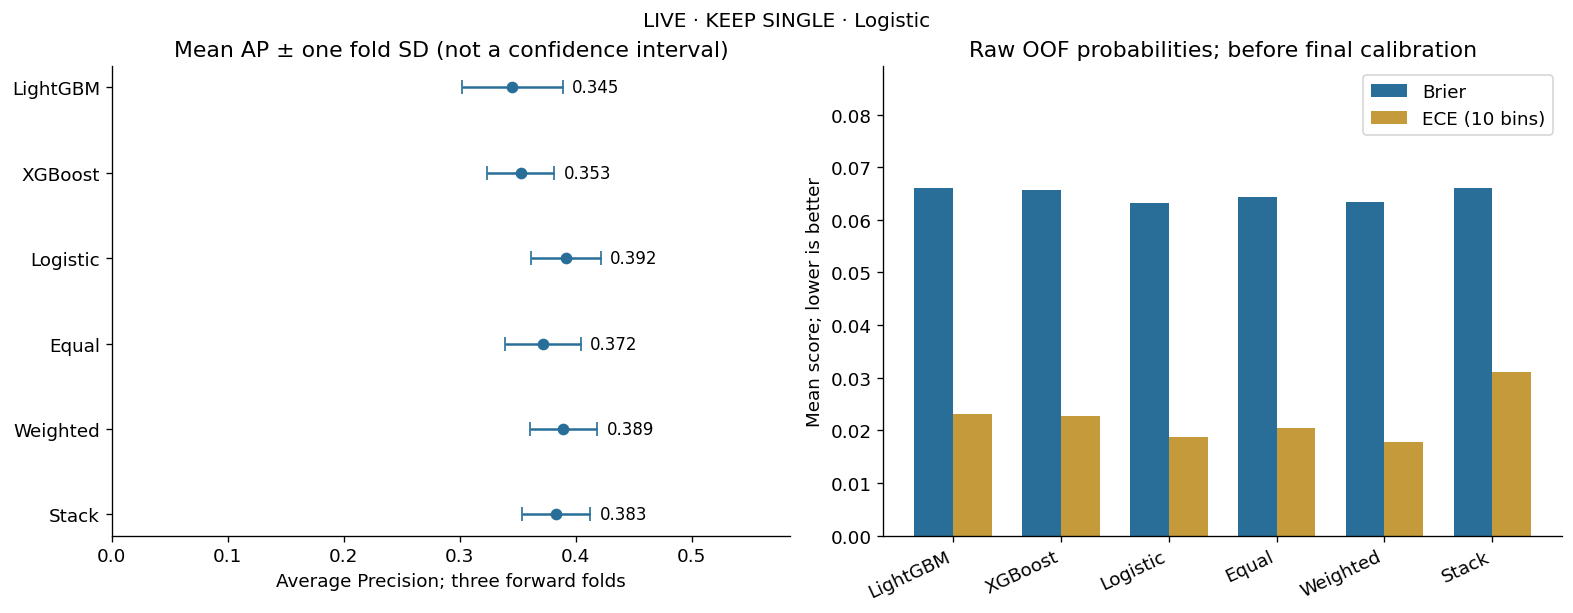

In [6]:
comparison, gate = worth_it(fold_scores, config)
display(comparison.round(5)); print(gate["decision"], "→", gate["chosen"])
fig, axes = plt.subplots(1,2,figsize=(13,5),layout="constrained")
order=list(BASE+ENSEMBLES)
for i,name in enumerate(order):
    row=comparison.set_index("candidate").loc[name]
    axes[0].errorbar(row.mean_ap,i,xerr=row.fold_sd,fmt="o",color="#286e98",capsize=4)
    axes[0].text(row.mean_ap+row.fold_sd+.008,i,f"{row.mean_ap:.3f}",va="center",fontsize=10)
axes[0].set_yticks(range(6),order); axes[0].invert_yaxis(); axes[0].set_xlim(0,min(1,comparison.mean_ap.max()+comparison.fold_sd.max()+.15))
axes[0].set_title("Mean AP ± one fold SD (not a confidence interval)"); axes[0].set_xlabel("Average Precision; three forward folds")
x=np.arange(6)
axes[1].bar(x-.18,comparison.mean_brier,.36,label="Brier",color="#286e98")
axes[1].bar(x+.18,comparison.mean_ece,.36,label="ECE (10 bins)",color="#c49a3a")
axes[1].set_xticks(x,order,rotation=25,ha="right"); axes[1].set_ylabel("Mean score; lower is better")
axes[1].set_title("Raw OOF probabilities; before final calibration"); axes[1].legend()
axes[1].set_ylim(0, max(comparison.mean_brier.max(),comparison.mean_ece.max())*1.35)
fig.suptitle(f"{SOURCE} · {gate['decision']} · {gate['chosen']}",fontsize=12)
fig.savefig(ARTIFACTS / "day5_ensemble_comparison.png",bbox_inches="tight"); plt.show()

,threshold,tp,fp,fn,tn,flagged,flag_fraction,recall,precision,false_positive_rate,accuracy,loss_units,loss_units_per_10000,capacity_feasible,max_period_flag_fraction,rows,source
0,0.16892,84,161,95,1815,245,0.11369,0.46927,0.34286,0.08148,0.88121,1111.0,5155.45244,True,0.11749,2155,LIVE


,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,537,489,48,63,39,24,0.0798,0.5000,False,LIVE
1,western,533,486,47,71,50,21,0.1029,0.4468,False,LIVE
2,eastern,542,507,35,48,32,16,0.0631,0.4571,False,LIVE
3,other,543,494,49,63,40,23,0.0810,0.4694,False,LIVE


,false_negative_cost,false_positive_cost,fixed_threshold,loss_units
0,8,1,0.168922,921
1,10,1,0.168922,1111
2,12,1,0.168922,1301


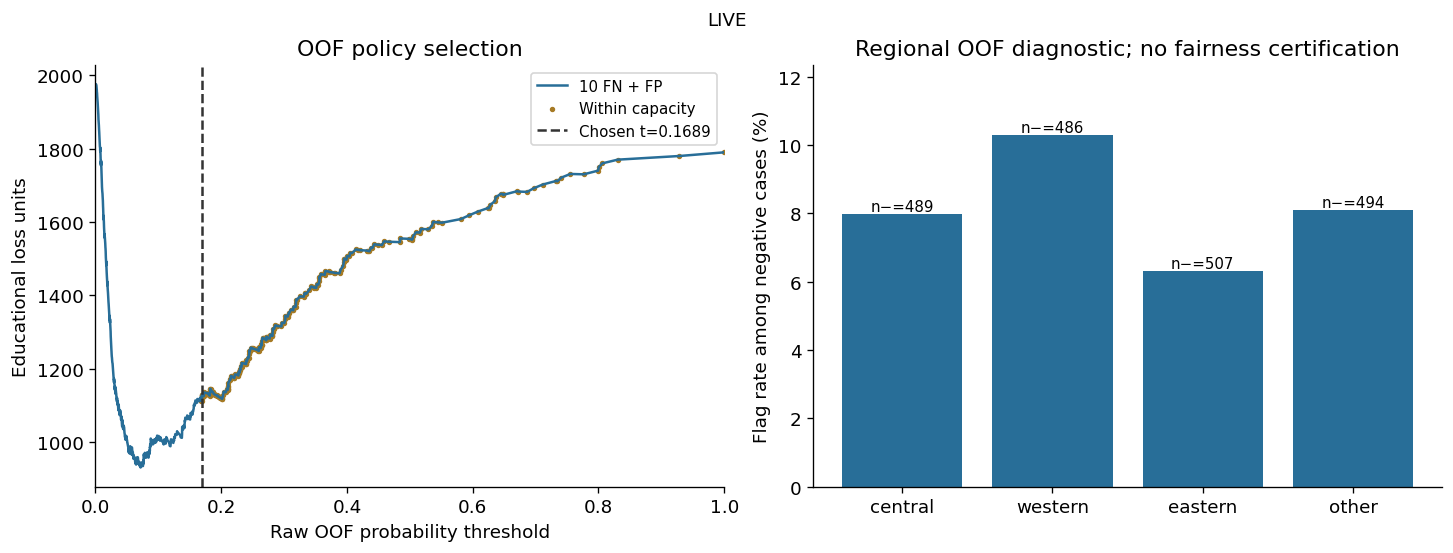

In [7]:
policy = CostPolicy()
selected = selected_oof(oof, gate["chosen"])
sweep = threshold_sweep(selected, policy)
threshold_choice = select_threshold(sweep)
raw_threshold = float(threshold_choice["threshold"])
regional, regional_summary = region_audit(selected, raw_threshold)
period_capacity = period_audit(selected, raw_threshold, policy)
sensitivity = pd.DataFrame([{"false_negative_cost":c,"false_positive_cost":1,
    "fixed_threshold":raw_threshold,"loss_units":c*int(threshold_choice["fn"])+int(threshold_choice["fp"])} for c in (8,10,12)])
display(pd.DataFrame([threshold_choice]).round(5)); display(regional.round(4)); display(sensitivity)
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
axes[0].plot(sweep.threshold,sweep.loss_units,color="#286e98",label="10 FN + FP")
feasible=sweep[sweep.capacity_feasible]
axes[0].scatter(feasible.threshold,feasible.loss_units,s=5,color="#a67a24",label="Within capacity")
axes[0].axvline(raw_threshold,color="#333",ls="--",label=f"Chosen t={raw_threshold:.4f}")
axes[0].set(xlim=(0,1),xlabel="Raw OOF probability threshold",ylabel="Educational loss units",title="OOF policy selection"); axes[0].legend(fontsize=9)
axes[1].bar(regional.region,regional.false_positive_rate*100,color="#286e98")
axes[1].set(ylabel="Flag rate among negative cases (%)",title="Regional OOF diagnostic; no fairness certification")
for i,r in regional.iterrows(): axes[1].text(i,r.false_positive_rate*100,f"n−={r.negatives}",ha="center",va="bottom",fontsize=9)
axes[1].margins(y=.2)
fig.suptitle(SOURCE,fontsize=11); fig.savefig(ARTIFACTS / "day5_policy_regions.png",bbox_inches="tight"); plt.show()



,rows,positives,prevalence,roc_auc,average_precision,brier,log_loss,ece,bins,binning
raw_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.076473,0.266489,0.021121,10,"fixed width, [lower, upper); final bin includes 1"
sigmoid_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.078058,0.277296,0.034871,10,"fixed width, [lower, upper); final bin includes 1"


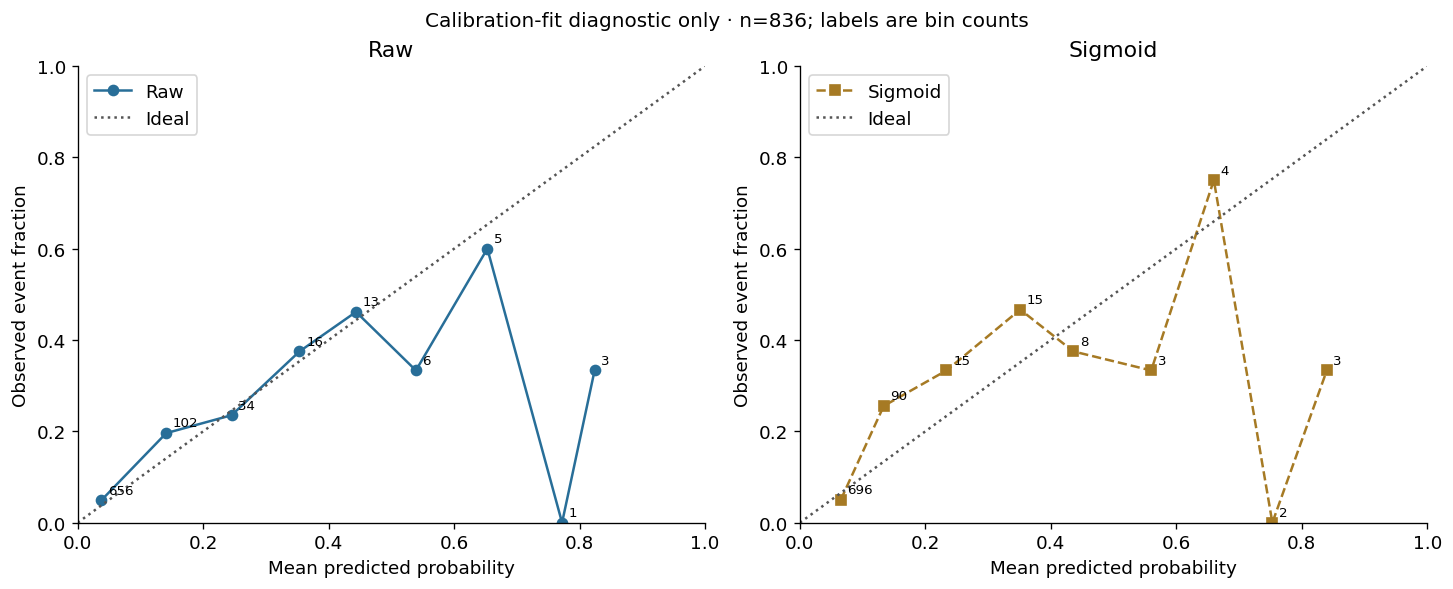

Final model and sigmoid frozen; transported threshold: 0.12225843144286948


In [9]:
if SOURCE == "LIVE":
    final_model, mapping, calibration_predictions, final_provenance = fit_final(pool, calibration, contract, gate["chosen"], config)
    calibrated_threshold = transport_threshold(raw_threshold, mapping)
    final_model_manifest = export_model(final_model, mapping, contract, ARTIFACTS / "final_model")
    calibration_diagnostics = {name:probability_metrics(calibration_predictions[TARGET],calibration_predictions[column])
        for name,column in [("raw_fit_diagnostic","raw_probability"),("sigmoid_fit_diagnostic","probability")]}
    bins = pd.concat([reliability_table(calibration_predictions[TARGET],calibration_predictions[column]).assign(series=name)
        for name,column in [("Raw","raw_probability"),("Sigmoid","probability")]],ignore_index=True)
    display(pd.DataFrame(calibration_diagnostics).T.round(5))
    fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
    for ax,name,style,color in [(axes[0],"Raw","o-","#286e98"),(axes[1],"Sigmoid","s--","#a67a24")]:
        table=bins[(bins.series==name)&(bins['count']>0)]
        ax.plot(table.mean_probability,table.observed_rate,style,label=name,color=color)
        for row in table.itertuples(): ax.annotate(str(row.count),(row.mean_probability,row.observed_rate),xytext=(4,4),textcoords="offset points",fontsize=8)
        ax.plot([0,1],[0,1],":",color="#555",label="Ideal")
        ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted probability",ylabel="Observed event fraction",title=name)
        ax.legend()
    fig.suptitle(f"Calibration-fit diagnostic only · n={len(calibration)}; labels are bin counts",fontsize=12)
    fig.savefig(ARTIFACTS / "day5_calibration_fit.png",bbox_inches="tight"); plt.show()
    print("Final model and sigmoid frozen; transported threshold:", calibrated_threshold)
else:
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE — final fitting, inference and submission are skipped.")

,application_id,probability,decision
0,CH-000278,0.114104,0
1,CH-001412,0.120922,0
2,CH-001444,0.055587,0
3,CH-002174,0.053426,0
4,CH-002260,0.077174,0


,rows,capacity,threshold_eligible,flagged,removed_by_cap,boundary_score,within_capacity,tie_policy,batch_policy
0,2500,300,330,300,30,0.129908,True,retain entire equal-score blocks; drop boundar...,"threshold first, then probability-descending f..."


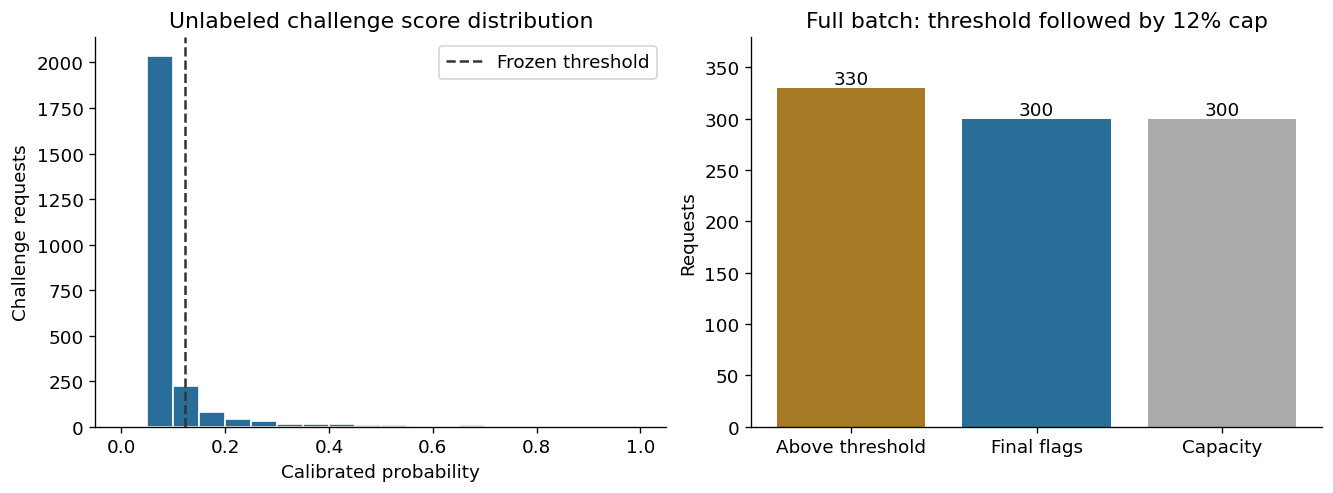

In [10]:
if SOURCE == "LIVE":
    from inference import predict
    predictions = predict(challenge, ARTIFACTS / "final_model")
    submission, batch_audit = apply_batch_policy(predictions, calibrated_threshold, policy)
    validate_submission(submission, challenge, calibrated_threshold, policy)
    expected = map_probability(final_model.predict_proba(challenge[[f['name'] for f in contract['features']]])[:,1], mapping)
    assert np.allclose(predictions.probability, expected, rtol=0, atol=1e-12)
    display(submission.head()); display(pd.DataFrame([batch_audit]))
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
    axes[0].hist(predictions.probability,bins=np.linspace(0,1,21),color="#286e98",edgecolor="white")
    axes[0].axvline(calibrated_threshold,color="#333",ls="--",label="Frozen threshold")
    axes[0].set(xlabel="Calibrated probability",ylabel="Challenge requests",title="Unlabeled challenge score distribution");axes[0].legend()
    axes[1].bar(["Above threshold","Final flags","Capacity"],[batch_audit['threshold_eligible'],batch_audit['flagged'],batch_audit['capacity']],color=["#a67a24","#286e98","#aaa"])
    axes[1].set(ylabel="Requests",title="Full batch: threshold followed by 12% cap")
    for i,n in enumerate([batch_audit['threshold_eligible'],batch_audit['flagged'],batch_audit['capacity']]): axes[1].text(i,n,str(n),ha="center",va="bottom")
    axes[1].margins(y=.15);fig.savefig(ARTIFACTS / "day5_challenge_capacity.png",bbox_inches="tight");plt.show()
else:
    print("No challenge predictions are produced from the educational example.")

In [11]:

responses = {
    "ensemble_reason": (
        "The project compares individual models and an ensemble "
        "for predicting late monthly payments such as electricity, "
        "water, rent, and installments. The final choice should "
        "balance average precision (AP), fold standard deviation, "
        "calibration quality, and model complexity. "
        "Selected model: [MODEL]. "
        "AP: [VALUE], fold SD: [VALUE], "
        "calibration score: [VALUE]. "
        "A more complex ensemble is justified only if its "
        "measured improvement is meaningful."
    ),

    "validation_limits": (
        "Nested forward out-of-fold validation helps evaluate "
        "future payment-risk predictions without training on "
        "later observations. Customer separation reduces "
        "information leakage. However, OOF results depend on "
        "the selected folds, observation periods, and eligible "
        "records. They cannot guarantee future performance."
    ),

    "calibration_limits": (
        "Calibration was fitted using data held out from "
        "model training. However, calibration diagnostics "
        "computed on those same calibration-fit rows are not "
        "an independent final evaluation. "
        "An untouched future period is needed to assess "
        "probability reliability. "
        "Measured calibration results: [VALUES]."
    ),

    "capacity_fairness": (
        "The payment-risk review policy must respect the "
        "full monthly review capacity. "
        "Total applications: [N], review capacity: [N], "
        "selected flags: [N], removed flags: [N]. "
        "Regional false positive rates must be compared using "
        "the actual number of false positives and negative "
        "cases in each region. "
        "The observed regional FPR gap is [VALUE]. "
        "Small regional samples limit fairness conclusions."
    ),

    "explanation_scope": (
        "Day 4 explanations describe the model evaluated "
        "during Day 4. If the final model is different, "
        "those SHAP explanations cannot automatically "
        "be transferred to the final model. "
        "Feature importance, local SHAP values, "
        "calibration, reason statements, and regional "
        "behavior must be rechecked for the final version."
    ),

    "intended_use": (
        "This is a fictional educational machine learning "
        "project developed during SDAIA training. "
        "Its proposed application is predicting the risk "
        "of delayed monthly household payments, including "
        "electricity, water, rent, and loan installments. "
        "The training data do not establish performance "
        "on real household bills. The model must not "
        "be used for real lending decisions, automatic "
        "payment restrictions, or financial penalties."
    ),

    "monitoring_plan": (
        "Model monitoring should include monthly checks "
        "for feature drift, prediction drift, review "
        "capacity, calibration, average precision, "
        "and regional false positive rates. "
        "Unexpected changes should trigger investigation "
        "before updating the model or decision threshold."
    ),

    "executive_summary_ar": (
        "يهدف المشروع إلى التنبؤ بمخاطر تأخر الأفراد في "
        "سداد الالتزامات الشهرية مثل الكهرباء والمياه "
        "والإيجار والأقساط باستخدام تعلم الآلة. "
        "يعتمد اختيار النموذج النهائي على متوسط الدقة "
        "AP واستقرار النتائج والمعايرة وتعقيد النموذج. "
        "النموذج المختار: [MODEL]، "
        "وقيمة AP: [VALUE]، "
        "والسعة المتاحة للمراجعة: [N]. "
        "المشروع تجربة تعليمية ولا يمثل نظاماً مالياً "
        "جاهزاً للاستخدام الفعلي."
    ),

    "executive_summary_en": (
        "This project explores machine learning for "
        "predicting delayed monthly financial obligations. "
        "The final model is selected using AP, validation "
        "stability, calibration, and operational complexity. "
        "Selected model: [MODEL], AP: [VALUE], "
        "review capacity: [N]. "
        "The experiment is educational and does not "
        "establish real-world financial reliability."
    )
}

checkpoint = reflection_check(responses, SOURCE)

print(checkpoint["status"], "| Missing:", checkpoint["missing"])
print("Upload your previous daily ZIPs here if available:", ROOT)


READY_FOR_REVIEW | Missing: []
Upload your previous daily ZIPs here if available: /content/tamweel


In [13]:
def clean_json(value):
    if isinstance(value,dict): return {str(k):clean_json(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [clean_json(v) for v in value]
    if isinstance(value,np.generic): return clean_json(value.item())
    if isinstance(value,float) and not np.isfinite(value): return None
    return value

tables = {"day5_roles.csv":roles,"day5_oof_predictions.csv":oof,"day5_fold_scores.csv":fold_scores,
    "ensemble_comparison.csv":comparison,"day5_threshold_sweep.csv":sweep,"day5_region_audit.csv":regional,
    "day5_period_capacity.csv":period_capacity,"day5_cost_sensitivity.csv":sensitivity}
for name,table in tables.items(): table.to_csv(ARTIFACTS / name,index=False)
correlation.to_csv(ARTIFACTS / "day5_probability_correlation.csv")
residual_correlation.to_csv(ARTIFACTS / "day5_residual_correlation.csv")
run = {"technical_status":"TECHNICAL_READY" if SOURCE=="LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE",
    "source":SOURCE,"chosen":gate['chosen'],"decision":gate['decision'],"config":asdict(config),
    "learner_status":checkpoint['status'],"lab_revision":LAB_REVISION,"support_hashes":SUPPORT_HASHES,
    "previous_support":PREVIOUS_SUPPORT,"data_revision":COURSE_REVISION,"python":platform.python_version(),
    "elapsed_seconds":round(time.perf_counter()-STARTED,2),"challenge_labels_used":False,"automatic_grade":None}
for name,obj in {"day5_run.json":run,"day5_reflection.json":{"responses":responses,"checkpoint":checkpoint},
    "day5_oof_provenance.json":oof_provenance,"day5_ensemble_gate.json":gate}.items(): write_json(ARTIFACTS / name,clean_json(obj))
if SOURCE != "LIVE":
    example_zip=ROOT / "day5_example_analysis.zip"
    with zipfile.ZipFile(example_zip,"w",zipfile.ZIP_DEFLATED) as z:
        for name in [*tables,"day5_run.json","day5_ensemble_gate.json","day5_diversity.png","day5_ensemble_comparison.png","day5_policy_regions.png"]:
            z.write(ARTIFACTS/name,name)
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE — comparison only; no model, submission or project bundle exported.")
    display(FileLink(str(example_zip)))
else:
    submission.to_csv(SUBMISSION / "submission.csv",index=False)
    calibration_predictions.to_csv(ARTIFACTS / "day5_calibration_predictions.csv",index=False)
    bins.to_csv(ARTIFACTS / "day5_calibration_fit_bins.csv",index=False)
    final_policy={"raw_oof_threshold":raw_threshold,"calibrated_threshold":calibrated_threshold,
        "cost_policy":asdict(policy),"mapping":mapping,"batch_audit":batch_audit}
    final_metrics={"gate":gate,"oof_threshold_selection":threshold_choice,"regional_oof":regional_summary,
        "calibration_fit_diagnostics":calibration_diagnostics,"challenge_metrics":None,
        "challenge_metrics_reason":"Labels unavailable; no AP/loss/FPR claimed.","challenge_batch":batch_audit}
    write_json(ARTIFACTS / "final_policy.json",clean_json(final_policy))
    write_json(ARTIFACTS / "final_metrics.json",clean_json(final_metrics))
    write_json(ARTIFACTS / "day5_final_provenance.json",clean_json(final_provenance))
    reproduced=replay_submission(ROOT)
    assert np.allclose(reproduced.probability,submission.probability,rtol=0,atol=1e-12)
    assert np.array_equal(reproduced.decision,submission.decision)
    answer=lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
    card = f"""# بطاقة النموذج | Model Card
## الحالة
{checkpoint['status']} — جودة التفسير تحتاج مراجعة بشرية، وليست درجة آلية.
## الغرض والاستخدام | Purpose and use
{answer('intended_use')}
بيانات Tamweel Lite اصطناعية؛ الهدف حدث خلال 90 يومًا بعد الطلب. 22 خاصية متاحة وقت الطلب؛ لا معرفات أو تواريخ أو هدف في المدخلات. الاستخدام التعليمي فقط؛ لا قرارات تمويل فعلية.
## البيانات والتحقق | Data and validation
حوض التدريب والاختيار: {len(pool)} طلبًا. المعايرة: {len(calibration)} طلبًا و{int(calibration[TARGET].sum())} موجبًا. حجز عملاء المعايرة، 90 يومًا لنضج التسميات، وOOF أمامي متداخل مع فصل العملاء في المستويين. طيات المقارنة: 2023Q1 و2023Q3 و2024Q1. نستبعد النتائج التي لم تنضج قبل الأدوار التالية؛ آخر بيانات التدريب لا تستخدم تلقائيًا.
{answer('validation_limits')}
## النموذج والقرار | Model selection
{gate['decision']} / {gate['chosen']}. انحراف AP المرجعي: {gate['fold_sd_reference']:.6f}. ارجع إلى artifacts/ensemble_comparison.csv وday5_fold_scores.csv للأرقام الكاملة.
{answer('ensemble_reason')}
## المعايرة | Calibration
Sigmoid على عينة محجوزة من التدريب والاختيار؛ الرسم والمقاييس تشخيص على عينة تعلم المعاير، وليسا اختبارًا مستقلاً. لا ادعاء بتحسن على تحدٍّ مجهول التسميات.
{answer('calibration_limits')}
## السياسة والسعة والمناطق | Policy and regions
خسارة 10 FN + FP، عتبة OOF الخام {raw_threshold:.17g} والمنقولة {calibrated_threshold:.17g}. سعة الدفعة {batch_audit['capacity']}؛ المرشحون {batch_audit['threshold_eligible']}؛ الإشارات النهائية {batch_audit['flagged']}. كتلة الدرجات المتساوية لا تقسم. 1=إشارة مراجعة تعليمية، 0=عدم رفع الإشارة.
{answer('capacity_fairness')}
## التفسير وحدوده | Explanation scope
تفسير اليوم الرابع يخص نموذج اليوم الرابع؛ لا يُنسب تلقائيًا إلى هذه النسخة. تغيير النموذج أو خصائصه أو معايرته يستلزم مراجعة التفسير.
{answer('explanation_scope')}
## المتابعة والقيود | Monitoring and limitations
{answer('monitoring_plan')}
OOF يستخدم للاختيار، وثلاث فترات ليست اختبار دلالة. العتبة قد تتغير سعتها عند نقلها إلى نموذج معاد التدريب. لا تسميات للتحدي، ولا مقاييس أداء أو شهادة عدالة له. البيانات لا تمثل أشخاصًا أو مناطق حقيقية.
## إعادة الإنتاج | Reproducibility
seed={config.seed}; trees={config.trees}; CPU مجاني. الإصدارات في artifacts/environment.json. المصادر/bصماتها في artifacts/day5_run.json. النموذج artifacts/final_model؛ inference.predict يعيد ID واحتمالًا؛ السياسة تطبق بعد جمع الدفعة. replay_final يعيد التنبؤ المحفوظ؛ rebuild_final يعيد التدريب. لا تدرب النموذج بعد تثبيت المعاير.
## ملكيتك للتسليم | Submission ownership
أكمل أدلة الأيام السابقة والعرض، واحفظ الدفتر المنفذ، ثم سجل SHA وtag مستودعك في قناة التسليم الخاصة. دعم الدورة {LAB_REVISION} ليس SHA تسليمك.
"""
    (REPORTS / "MODEL_CARD.md").write_text(card.replace("bصماتها","بصماتها"),encoding="utf-8")
    (REPORTS / "ENSEMBLE_DECISION.md").write_text(f"# قرار التجميع\n\n{gate['decision']} — {gate['chosen']}\n\n{answer('ensemble_reason')}\n\n{answer('validation_limits')}\n\nالدليل: artifacts/ensemble_comparison.csv وday5_ensemble_gate.json. SD وصفي، وليس اختبار دلالة.\n",encoding="utf-8")
    (ROOT / "PROJECT_README.md").write_text(f"# Tamweel Lite | مشروعك النهائي\n\n## الملخص التنفيذي\n{answer('executive_summary_ar')}\n\n## Executive summary\n{answer('executive_summary_en')}\n\nDecision: {gate['decision']} / {gate['chosen']}. Full-batch flags: {batch_audit['flagged']}/{len(challenge)}.\n\nاقرأ reports/MODEL_CARD.md والسياسة في artifacts/final_policy.json. الحزمة للتدريب؛ ليست نتيجة تقييم نهائية أو إثبات تسليم. ادمج أدلة أيامك السابقة واحفظ الدفتر المنفذ والعرض.\n",encoding="utf-8")
    for day in range(1,5):
        archive=ROOT / f"day{day}_artifacts.zip"
        if archive.exists(): import_daily_evidence(archive,ROOT / "evidence" / f"day{day}")
    completeness=evidence_status(ROOT)
    full_ready=checkpoint['status']=="READY_FOR_REVIEW" and all(r['status'] in ("READY_FOR_REVIEW","PRESENT_REQUIRES_REVIEW") for r in completeness)
    full_status="READY_FOR_HUMAN_REVIEW" if full_ready else "PROJECT_WORK_REQUIRED"
    write_json(ARTIFACTS / "day5_project_check.json",{"status":full_status,"items":completeness,"automatic_grade":None,"receipt":False})
    display(pd.DataFrame(completeness)[['item','status']])
    bundle_files=["PROJECT_README.md","reports/MODEL_CARD.md","reports/ENSEMBLE_DECISION.md","submission/submission.csv",
        "requirements-colab.txt","constraints.txt","data/data_contract.json","data/data_manifest.json","data/tamweel_train.csv","data/tamweel_challenge.csv",
        "presentation/FINAL_PRESENTATION_TEMPLATE.md","presentation/FINAL_PRESENTATION_GUIDE.md",*PREVIOUS_SUPPORT.keys(),*[p for p in SUPPORT_HASHES if p.startswith('scripts/')]]
    artifact_names=[*tables,"day5_probability_correlation.csv","day5_residual_correlation.csv","day5_run.json","day5_reflection.json",
        "day5_oof_provenance.json","day5_ensemble_gate.json","final_policy.json","final_metrics.json","day5_final_provenance.json",
        "day5_calibration_predictions.csv","day5_calibration_fit_bins.csv","day5_project_check.json","environment.json",
        "day5_diversity.png","day5_ensemble_comparison.png","day5_policy_regions.png","day5_calibration_fit.png","day5_challenge_capacity.png"]
    bundle_files += ["artifacts/"+name for name in artifact_names]
    bundle_files += ["artifacts/final_model/"+name for name in [*final_model_manifest,"model_manifest.json"]]
    for folder in [ROOT/'evidence',ROOT/'notebooks']:
        if folder.exists(): bundle_files += [p.relative_to(ROOT).as_posix() for p in folder.rglob('*') if p.is_file() and p.suffix in ('.csv','.json','.png','.md','.npz','.txt','.ipynb')]
    if (ROOT/'presentation/final_presentation.pdf').is_file(): bundle_files.append('presentation/final_presentation.pdf')
    manifest,bundle_path=create_bundle(ROOT,bundle_files,{"source":SOURCE,"lab_revision":LAB_REVISION,"day5_learner_status":checkpoint['status'],
        "project_status":full_status,"challenge_sha256":sha256((ROOT/'data/tamweel_challenge.csv').read_bytes()).hexdigest()})
    print("REPLAY_MATCH |",verify_bundle(bundle_path),"|",full_status)
    display(FileLink(str(bundle_path)))
    print("احفظ الدفتر المنفذ وأكمل إجاباتك وأدلة الأيام السابقة والعرض؛ ثم ارفع الملفات إلى مشروعك نفسه.")

,item,status
0,day1_learner_evidence,MISSING
1,day2_learner_evidence,MISSING
2,day3_learner_evidence,MISSING
3,day4_learner_evidence,MISSING
4,notebooks/01_baseline_boosting.ipynb,MISSING
5,notebooks/02_validation_tuning.ipynb,MISSING
6,notebooks/03_cost_sensitive_decision.ipynb,MISSING
7,notebooks/04_explain_calibrate.ipynb,MISSING
8,notebooks/05_final_model.ipynb,MISSING
9,presentation/final_presentation.pdf,MISSING


REPLAY_MATCH | {'status': 'BUNDLE_BYTES_VERIFIED', 'files': 48, 'sha256': 'dd53a124a2ac4afd59d55d600621706f8693e55e4cd72564db44a24808de4773'} | PROJECT_WORK_REQUIRED


/content/tamweel/submission/project_bundle.zip

احفظ الدفتر المنفذ وأكمل إجاباتك وأدلة الأيام السابقة والعرض؛ ثم ارفع الملفات إلى مشروعك نفسه.
